In [21]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE

X_train = pd.read_csv("../data/X_train.csv")
X_test = pd.read_csv("../data/X_test.csv")
y_train = pd.read_csv("../data/y_train.csv")["Class"]
y_test = pd.read_csv("../data/y_test.csv")["Class"]

print(X_train.shape, X_test.shape)
print("Fraud in test set:", y_test.sum())

(226980, 30) (56746, 30)
Fraud in test set: 95


In [22]:
results = []

def evaluate(name, model):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    scores = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob),
    }
    results.append(scores)

    for k, v in scores.items():
        print(f"{k:10}: {v:.4f}" if k != "Model" else f"--- {v} ---")

    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=["Genuine", "Fraud"]).plot(cmap="Blues")
    plt.title(name)
    plt.show()

--- Dummy (always genuine) ---
Accuracy  : 0.9983
Precision : 0.0000
Recall    : 0.0000
F1        : 0.0000
ROC-AUC   : 0.5000
PR-AUC    : 0.0017


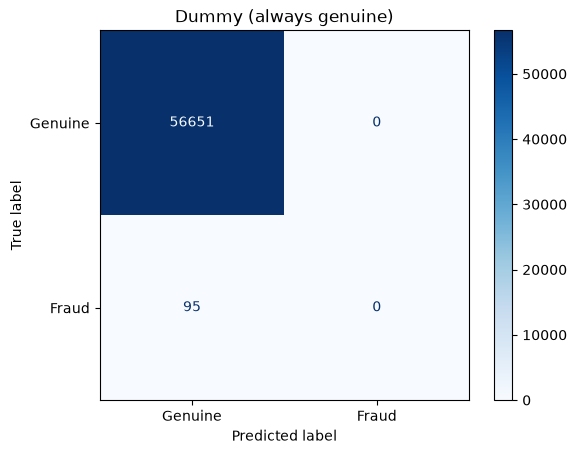

In [23]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
evaluate("Dummy (always genuine)", dummy)

--- LogReg (plain) ---
Accuracy  : 0.9991
Precision : 0.8462
Recall    : 0.5789
F1        : 0.6875
ROC-AUC   : 0.9598
PR-AUC    : 0.6894


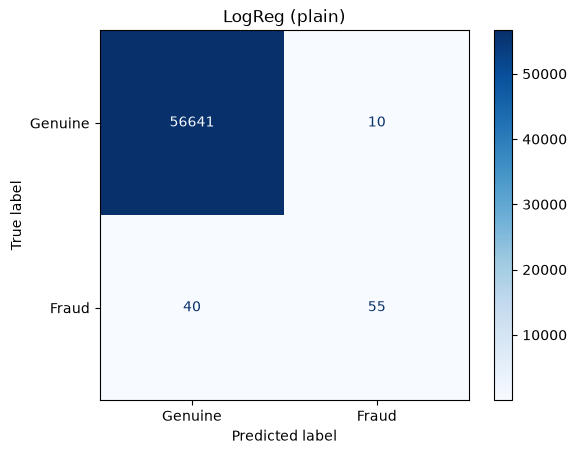

In [24]:
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)
evaluate("LogReg (plain)", lr)

--- LogReg + class_weight ---
Accuracy  : 0.9749
Precision : 0.0554
Recall    : 0.8737
F1        : 0.1043
ROC-AUC   : 0.9655
PR-AUC    : 0.6731


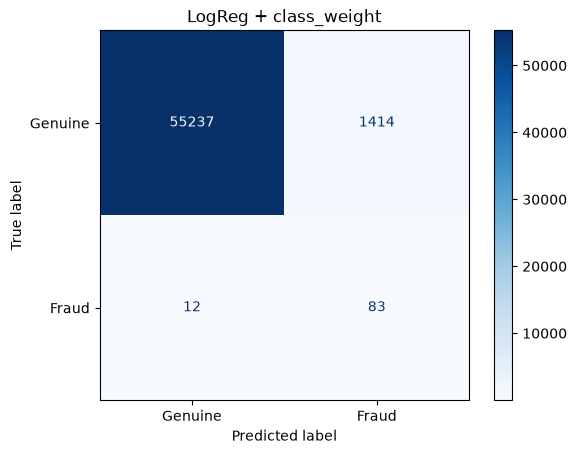

In [25]:
lr_weighted = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
lr_weighted.fit(X_train, y_train)
evaluate("LogReg + class_weight", lr_weighted)

After SMOTE: {0: 226602, 1: 226602}
--- LogReg + SMOTE ---
Accuracy  : 0.9737
Precision : 0.0530
Recall    : 0.8737
F1        : 0.1000
ROC-AUC   : 0.9608
PR-AUC    : 0.6758


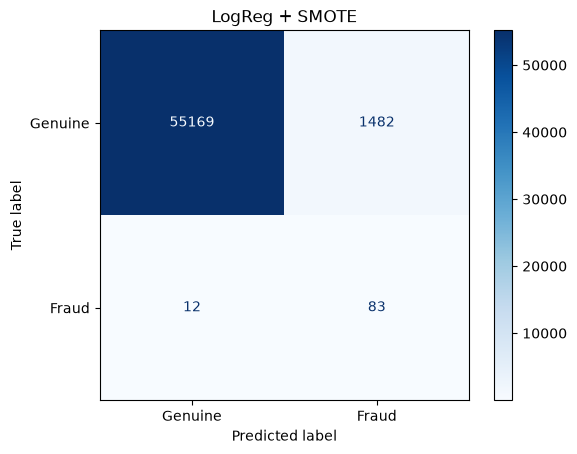

In [26]:
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_train, y_train)
print("After SMOTE:", y_res.value_counts().to_dict())

lr_smote = LogisticRegression(max_iter=1000, random_state=42)
lr_smote.fit(X_res, y_res)
evaluate("LogReg + SMOTE", lr_smote)

In [27]:
comparison = pd.DataFrame(results).set_index("Model").round(4)
comparison

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Dummy (always genuine),0.9983,0.0000,0.0000,0.0000,0.5000,0.0017
LogReg (plain),0.9991,0.8462,0.5789,0.6875,0.9598,0.6894
LogReg + class_weight,0.9749,0.0554,0.8737,0.1043,0.9655,0.6731
LogReg + SMOTE,0.9737,0.0530,0.8737,0.1000,0.9608,0.6758


## Findings
- Dummy model: 99.83% accuracy but 0% recall → accuracy is useless for imbalanced data.
- Plain Logistic Regression: precision 0.85, recall 0.58 → few false alarms but misses 42% of fraud.
- Class weights / SMOTE: recall rises to 0.87, but precision falls to ~0.05 (~1,400 false alarms).
- PR-AUC stays ~0.68 for all three → imbalance techniques shift the decision threshold; they don't make the model better at separating fraud.
- Next: stronger models (Random Forest, XGBoost) and threshold tuning.